## 신용평가와 모델 해석


### 신용평가와 예측 설명

신용평가는 돈을 빌리거나 외상으로 거래한 상대가 약속한 상환을 이행하지 못할 위험을 판단하는 일이다.
소득·부채·과거 상환 이력과 대출 금액·기간 등이 판단의 근거가 된다.

계약 정보와 이행 결과가 있는 데이터에서는 계약의 불량 여부를 예측하는 이진 분류 모델을 학습할 수 있다.
모델은 입력에서 학습한 패턴을 바탕으로 불량 클래스의 점수를 계산한다. 점수가 높을수록 모델이 해당 계약을 불량 쪽으로 판단한다.

예측 성능은 새로운 계약의 결과를 얼마나 잘 맞히는지 보여준다.
모델 해석은 어떤 입력을 사용하고, 각 입력이 계약의 점수에 어떻게 반영되는지 설명한다.
신용평가에서는 이 설명을 계약의 실제 정보와 대조해 판단 근거와 추가 확인할 내용을 살펴볼 수 있다.


### 패키지 설치

터미널에서 설치한다.

```bash
pip install shap
```


In [1]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
)


c:\Users\student\.pyenv\pyenv-win\versions\3.13.13\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### South German Credit 데이터 불러오기

South German Credit은 1973~1975년의 실제 신용 계약 1,000건을 담은 신용평가 데이터다. 한 행은 계약 한 건이며, 대출 금액·기간, 고객의 신용 이력·저축·고용 상태 등 20개 특성과 계약 이행 결과를 포함한다. 이 정보로 계약의 불량 여부를 예측한다.

계약 이행 양호 700건과 불량 300건으로 구성되어 있다.

출처: UCI Machine Learning Repository, South German Credit (2020), DOI 10.24432/C5QG88, CC BY 4.0.


In [2]:
data_url = "https://archive.ics.uci.edu/static/public/573/south%2Bgerman%2Bcredit%2Bupdate.zip"

# urlopen으로 연결하고 read()로 ZIP 바이트를 읽는다.
with urlopen(data_url, timeout=60) as response:
    archive_bytes = response.read()

# BytesIO는 바이트를 파일처럼 다루고, ZipFile은 ZIP을 연다.
with ZipFile(BytesIO(archive_bytes)) as archive:
    with archive.open("SouthGermanCredit.asc") as source:
        # sep=r"\s+": 하나 이상의 공백으로 열을 구분한다.
        credit = pd.read_csv(source, sep=r"\s+")

display(credit.head())


,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1


### 열 이름 바꾸기

독일어 열 이름을 영어로 바꾼다.


In [3]:
column_names = {
    "laufkont": "status",
    "laufzeit": "duration",
    "moral": "credit_history",
    "verw": "purpose",
    "hoehe": "amount",
    "sparkont": "savings",
    "beszeit": "employment_duration",
    "rate": "installment_rate",
    "famges": "personal_status_sex",
    "buerge": "other_debtors",
    "wohnzeit": "present_residence",
    "verm": "property",
    "alter": "age",
    "weitkred": "other_installment_plans",
    "wohn": "housing",
    "bishkred": "number_credits",
    "beruf": "job",
    "pers": "people_liable",
    "telef": "telephone",
    "gastarb": "foreign_worker",
    "kredit": "credit_risk"
}

# columns에 지정한 이름으로 열을 바꾼다.
credit = credit.rename(columns=column_names)
display(credit.head())


,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1


### 범주 코드와 정답 라벨 변환

`codetable.txt`를 기준으로 범주 코드를 해당 값으로 바꾼다. 불량 계약을 양성 클래스로 두기 위해 정답을 불량=1, 양호=0으로 변환한다.


In [4]:
category_names = {
    "status": {1: "no_account", 2: "negative_balance", 3: "balance_0_to_200_DM", 4: "balance_200_plus_or_salary"},
    "credit_history": {0: "past_payment_delay", 1: "critical_or_other_credit", 2: "no_credit_or_all_paid",
                       3: "existing_paid_to_date", 4: "all_paid_at_this_bank"},
    "purpose": {0: "other", 1: "new_car", 2: "used_car", 3: "furniture", 4: "radio_tv",
                5: "appliances", 6: "repairs", 7: "education", 8: "vacation", 9: "retraining", 10: "business"},
    "savings": {1: "unknown_or_no_account", 2: "below_100_DM", 3: "100_to_500_DM", 4: "500_to_1000_DM", 5: "1000_plus_DM"},
    "employment_duration": {1: "unemployed", 2: "below_1_year", 3: "1_to_4_years", 4: "4_to_7_years", 5: "7_plus_years"},
    "installment_rate": {1: "35_percent_plus", 2: "25_to_35_percent", 3: "20_to_25_percent", 4: "below_20_percent"},
    "personal_status_sex": {1: "male_divorced_or_separated", 2: "female_non_single_or_male_single",
                            3: "male_married_or_widowed", 4: "female_single"},
    "other_debtors": {1: "none", 2: "co_applicant", 3: "guarantor"},
    "present_residence": {1: "below_1_year", 2: "1_to_4_years", 3: "4_to_7_years", 4: "7_plus_years"},
    "property": {1: "unknown_or_no_property", 2: "car_or_other",
                 3: "building_society_savings_or_life_insurance", 4: "real_estate"},
    "other_installment_plans": {1: "bank", 2: "stores", 3: "none"},
    "housing": {1: "for_free", 2: "rent", 3: "own"},
    "number_credits": {1: "one", 2: "two_to_three", 3: "four_to_five", 4: "six_plus"},
    "job": {1: "unemployed_or_unskilled_non_resident", 2: "unskilled_resident",
            3: "skilled_employee_or_official", 4: "manager_self_employed_or_highly_qualified"},
    "people_liable": {1: "three_plus", 2: "zero_to_two"},
    "telephone": {1: "no", 2: "yes_under_customer_name"},
    "foreign_worker": {1: "yes", 2: "no"},
}

# map은 코드를 범주 이름으로 바꾼 Series를 반환한다.
for column, mapping in category_names.items():
    credit[column] = credit[column].map(mapping)

# 불량=1, 양호=0으로 변환한다.
credit["bad_credit"] = 1 - credit["credit_risk"]

# 원본 행 번호를 첫 열에 추가한다.
credit.insert(0, "record_id", np.arange(len(credit)))

CREDIT_NUMERIC = ['duration', 'amount', 'age']
CREDIT_CATEGORICAL = list(category_names)
CREDIT_FEATURES = CREDIT_NUMERIC + CREDIT_CATEGORICAL

display(credit.head())


,record_id,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,...,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk,bad_credit
0,0,no_account,18,all_paid_at_this_bank,used_car,1049,unknown_or_no_account,below_1_year,below_20_percent,female_non_single_or_male_single,...,21,none,for_free,one,skilled_employee_or_official,zero_to_two,no,no,1,0
1,1,no_account,9,all_paid_at_this_bank,other,2799,unknown_or_no_account,1_to_4_years,25_to_35_percent,male_married_or_widowed,...,36,none,for_free,two_to_three,skilled_employee_or_official,three_plus,no,no,1,0
2,2,negative_balance,12,no_credit_or_all_paid,retraining,841,below_100_DM,4_to_7_years,25_to_35_percent,female_non_single_or_male_single,...,23,none,for_free,one,unskilled_resident,zero_to_two,no,no,1,0
3,3,no_account,12,all_paid_at_this_bank,other,2122,unknown_or_no_account,1_to_4_years,20_to_25_percent,male_married_or_widowed,...,39,none,for_free,two_to_three,unskilled_resident,three_plus,no,yes,1,0
4,4,no_account,12,all_paid_at_this_bank,other,2171,unknown_or_no_account,1_to_4_years,below_20_percent,male_married_or_widowed,...,38,bank,rent,two_to_three,unskilled_resident,zero_to_two,no,yes,1,0


### 데이터의 변수

영어 이름으로 바꾼 21개 열은 다음과 같다.

| 영어 이름 | 의미 |
| --- | --- |
| `status` | 은행 계좌 상태·잔액 구간 |
| `duration` | 계약 기간(개월) |
| `credit_history` | 과거·진행 중인 신용 계약의 이행 이력 |
| `purpose` | 대출 목적 |
| `amount` | 변환된 대출 금액으로, 실제 통화 금액으로 해석할 수 없음 |
| `savings` | 저축 계좌·잔액 구간 |
| `employment_duration` | 현재 직장의 고용 기간 구간 |
| `installment_rate` | 가처분 소득 대비 할부금 비율 구간 |
| `personal_status_sex` | 성별·혼인 상태를 합친 범주 |
| `other_debtors` | 공동 채무자·보증인 여부 |
| `present_residence` | 현재 거주지의 거주 기간 구간 |
| `property` | 가장 가치가 큰 보유 자산의 유형 |
| `age` | 나이 |
| `other_installment_plans` | 다른 할부 거래의 제공 기관 |
| `housing` | 주거 형태(무상·임차·자가) |
| `number_credits` | 이 은행의 신용 계약 수 구간 |
| `job` | 직업 유형 |
| `people_liable` | 경제적으로 부양하는 사람 수 구간 |
| `telephone` | 본인 명의 유선전화 여부 |
| `foreign_worker` | 외국인 근로자 여부 |
| `credit_risk` | 계약 이행 결과(0=불량, 1=양호) |

계약 결과를 제외한 20개 변수를 모두 입력으로 사용한다.  
정답은 `credit_risk`에서 불량을 1로 변환한 `bad_credit`를 사용한다.

- `duration`, `amount`, `age`는 수치형으로 사용한다.
- 나머지 17개 변수는 범주형으로 원핫 인코딩한다.
- 정답 정보인 `credit_risk`, `bad_credit`와 행 추적용 `record_id`는 입력에서 제외한다.


In [5]:
X = credit[CREDIT_FEATURES]
y = credit["bad_credit"]

# crosstab은 원본 라벨과 변환한 라벨의 조합별 건수를 센다.
display(pd.crosstab(credit.credit_risk, y, rownames=["original_label"], colnames=["bad_credit"]))
print("계약 수:", len(credit), "입력 열:", len(CREDIT_FEATURES))


bad_credit,0,1
original_label,,
0,0,300
1,700,0


계약 수: 1000 입력 열: 20


### 학습·검증·테스트 분리

전체 계약을 학습 60%, 검증 20%, 테스트 20%로 나눈다.

평가 결과는 정해진 모델 설정과 한 번의 분할에서 얻은 값이다.


In [6]:
SEED = 42

# stratify: 클래스 비율 유지, random_state: 분할 재현.
X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

# 남은 80%의 25%를 검증용으로 분리하면 전체의 20%가 된다.
X_train, X_valid, y_train, y_valid = train_test_split(
    X_development, y_development, test_size=0.25,
    stratify=y_development, random_state=SEED
)
display(pd.DataFrame([
    {"split": name, "contracts": len(labels), "bad": int(labels.sum()),
     "bad_rate": labels.mean()}
    for name, labels in [("train", y_train), ("validation", y_valid), ("test", y_test)]
]))


,split,contracts,bad,bad_rate
0,train,600,180,0.3
1,validation,200,60,0.3
2,test,200,60,0.3


## 로지스틱 회귀로 신용평가하기

로지스틱 회귀는 입력별 가중치를 학습하고, 가중합을 0~1 사이의 클래스 점수로 바꾼다.
계약 기간·금액·신용 이력 같은 정보가 불량 점수에 반영되는 방향을 계수로 읽을 수 있다.

### 전처리와 학습

수치형 변수는 평균을 빼고 표준편차로 나누어 척도를 맞추고, 범주형 변수는 원핫 인코딩한다.


In [7]:
# ignore: 새 범주를 모두 0으로 표현, sparse_output=False: 밀집 배열 반환.
logistic_preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), CREDIT_NUMERIC),
    ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CREDIT_CATEGORICAL),
])

# C: 규제 강도의 역수, max_iter: 최적화 반복 상한.
logistic_model = Pipeline([
    ("preprocess", logistic_preprocessor),
    ("model", LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)),
])
logistic_model.fit(X_train, y_train)

# predict: 클래스 0·1을 담은 (계약 수,) 배열.
# 검증 계약의 클래스와 불량 점수를 구한다.
logistic_prediction = logistic_model.predict(X_valid)

# predict_proba: (계약 수, 클래스 수) 배열에서 불량=1의 열을 선택한다.
positive_column = list(logistic_model.classes_).index(1)
logistic_scores = logistic_model.predict_proba(X_valid)[:, positive_column]


### 로지스틱 회귀의 예측 결과

불량을 양성(1), 양호를 음성(0)으로 두고, 검증 계약의 예측 클래스와 실제 결과를 비교한다.
혼동 행렬은 실제 결과와 예측을 맞춰 네 종류로 나눈다.

| 항목 | 계약에 대한 의미 |
| --- | --- |
| TP | 실제 불량을 불량으로 예측 |
| FN(미탐) | 실제 불량을 양호로 예측 |
| FP(오탐) | 실제 양호를 불량으로 예측 |
| TN | 실제 양호를 양호로 예측 |

재현율(Recall) `TP / (TP + FN)`은 실제 불량 중 찾아낸 비율이다.
정밀도(Precision) `TP / (TP + FP)`는 불량으로 예측한 계약 중 실제 불량의 비율이다.
불량 계약의 누락과 양호 계약의 오판을 함께 확인한다.


,precision,recall,TP,FP,TN,FN
0,0.603774,0.533333,32,21,119,28


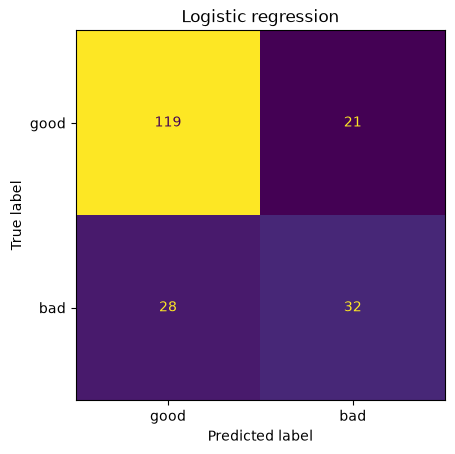

In [8]:
def credit_metrics(actual, prediction):
    # 행·열 순서는 양호, 불량이다. ravel()로 2×2 배열을 펼친다.
    tn, fp, fn, tp = confusion_matrix(actual, prediction, labels=[0, 1]).ravel()

    return {
        "precision": precision_score(actual, prediction, zero_division=0),
        "recall": recall_score(actual, prediction, zero_division=0),
        "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn),
    }


display(pd.DataFrame([credit_metrics(y_valid, logistic_prediction)]))

# 실제·예측 클래스로 혼동 행렬을 그린다.
ConfusionMatrixDisplay.from_predictions(
    y_valid, logistic_prediction, labels=[0, 1],
    display_labels=["good", "bad"], colorbar=False
)
plt.title("Logistic regression")
plt.show()


### 로지스틱 회귀의 오류 사례

오탐은 양호 계약을 불량으로 판단한 사례이고, 미탐은 불량 계약을 양호로 판단한 사례다.
오류 표에서 실제 결과와 예측을 읽고 어떤 오류인지 구분한다.


In [9]:
logistic_results = pd.DataFrame({
    "record_id": credit.loc[X_valid.index, "record_id"].to_numpy(),
    "actual": y_valid.to_numpy(),
    "prediction": logistic_prediction,
    "bad_class_score": logistic_scores,
})
logistic_results.index.name = "validation_position"

# 실제 라벨과 예측이 다른 계약을 고른다.
logistic_errors = logistic_results.loc[logistic_results.actual != logistic_results.prediction]
print("오류 계약 수:", len(logistic_errors))
display(logistic_errors.head(5))


오류 계약 수: 49


,record_id,actual,prediction,bad_class_score
validation_position,,,,
8,182,0,1,0.556739
21,927,1,0,0.464727
24,825,1,0,0.224137
25,512,0,1,0.565525
34,881,1,0,0.097441


### 로지스틱 회귀의 계수 읽기

다른 입력을 고정했을 때 계수의 부호는 다음과 같이 읽는다.

- 양수: 해당 입력값이 커질수록 불량 점수가 높아진다.
- 음수: 해당 입력값이 커질수록 불량 점수가 낮아진다.

예를 들어 계약 기간의 계수가 양수라면, 다른 조건이 같을 때 기간이 긴 계약에 더 높은 불량 점수를 준다.
원핫 입력은 해당 범주에 속할 때 1이 되어 그 계수가 가중합에 더해진다.
계수가 0에 가까울수록, 다른 입력을 고정했을 때 해당 입력의 한 단위 변화가 가중합에 미치는 영향이 작다.

표와 그래프에서 양수·음수 계수를 하나씩 골라 어떤 입력에 곱해지는 가중치인지 확인한다.

,coefficient
category__purpose_business,-1.101473
category__purpose_new_car,-1.060370
category__purpose_other,0.886726
category__credit_history_critical_or_other_credit,0.852159
category__status_balance_200_plus_or_salary,-0.824573
category__savings_unknown_or_no_account,0.768874
category__purpose_repairs,0.731484
category__credit_history_all_paid_at_this_bank,-0.722787
category__status_no_account,0.707657
category__savings_500_to_1000_DM,-0.639718


,coefficient
category__number_credits_two_to_three,-0.003816
category__purpose_retraining,-0.008795
numeric__age,-0.010858
category__purpose_used_car,-0.010867
category__present_residence_4_to_7_years,0.023495
category__job_unskilled_resident,-0.023801
category__employment_duration_7_plus_years,0.038404
category__savings_100_to_500_DM,0.043325
category__housing_own,0.047712
category__personal_status_sex_female_single,-0.048102


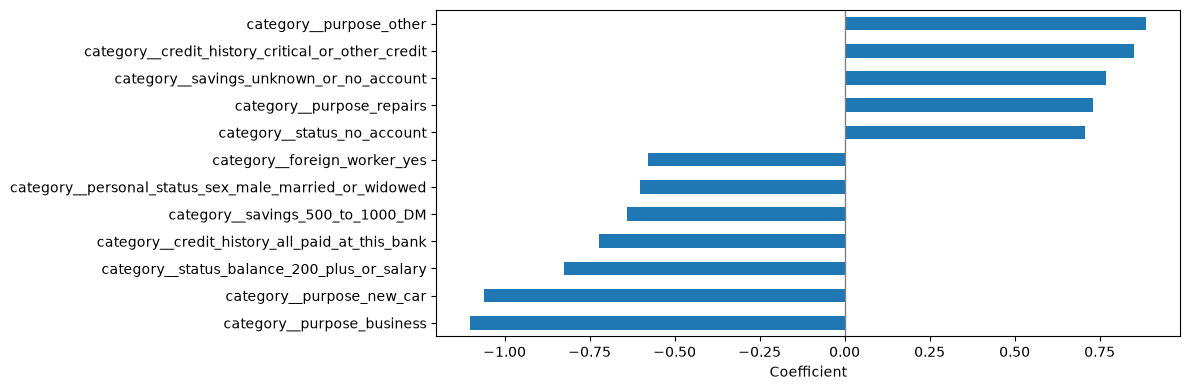

In [10]:
# named_steps로 파이프라인의 전처리와 모델을 꺼낸다.
logistic_preprocessor = logistic_model.named_steps["preprocess"]
logistic_estimator = logistic_model.named_steps["model"]
logistic_feature_names = logistic_preprocessor.get_feature_names_out()

# coef_: (1, 전처리 후 특성 수) 배열.
coefficients = pd.Series(logistic_estimator.coef_[0], index=logistic_feature_names, name="coefficient")

# 계수의 절댓값이 큰 순서로 정렬한다.
coefficient_table = coefficients.to_frame().assign(abs_coefficient=coefficients.abs())
coefficient_table = coefficient_table.sort_values("abs_coefficient", ascending=False)
display(coefficient_table[["coefficient"]].head(12))

# 0에 가까운 계수 12개를 확인한다.
display(coefficient_table.sort_values("abs_coefficient")[["coefficient"]].head(12))

# 절댓값이 큰 계수 12개를 부호와 함께 그린다.
top_coefficients = coefficient_table.head(12)["coefficient"].sort_values()
top_coefficients.plot.barh(figsize=(12, 4))
plt.axvline(0, color="gray", linewidth=1)
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()


학습된 모델의 계수를 다음과 같이 읽을 수 있다.

- `category__number_credits_two_to_three` — 계수가 약 -0.004로 0에 가까우므로, 이 은행의 신용 계약 수가 2~3건인 범주의 원핫 항이 가중합에 더하는 값은 작다.
- `category__purpose_new_car` — 계수가 약 -1.060로 음수이고 절댓값이 크므로, 새 차 구매 목적이라는 정보는 모델의 불량 점수를 낮추는 방향으로 크게 반영된다.
- `category__credit_history_critical_or_other_credit` — 계수가 약 0.852으로 양수이고 절댓값이 크므로, 신용 상태에 문제가 있거나 다른 금융기관에 대출이 있다는 정보는 모델의 불량 점수를 높이는 방향으로 크게 반영된다.


### SHAP으로 예측 이유 설명하기

SHAP은 학습된 모델이 계약 한 건에 내린 예측을 설명하는 방법이다.
대출 기간·계좌 상태·신용 이력 같은 정보가 그 계약의 불량 점수를 얼마나 높이거나 낮추는 방향으로 반영되었는지 보여준다.

### 기준값과 SHAP 값

기준값은 설명의 출발점이 되는 평균 모델 출력이다.
특성별 SHAP 값은 대출 기간·계좌 상태·신용 이력 같은 정보 각각이, 해당 계약의 예측을 기준값에서 얼마나 높이거나 낮추는 방향으로 기여했는지를 나타내는 값이다.
기준값에 이 양수·음수 기여를 모두 더하면 해당 계약의 모델 출력이 된다.

`기준값 + 특성별 SHAP 값의 합 = 해당 계약의 모델 출력`

- 양수: 불량 점수를 높이는 방향으로 기여한다.
- 음수: 불량 점수를 낮추는 방향으로 기여한다.
- 0에 가까운 값: 해당 계약의 예측에 작게 기여한다.
- 절댓값이 큰 값: 해당 계약의 예측에 크게 기여한다.


### 로지스틱 회귀의 SHAP

beeswarm은 여러 계약의 기여도를 모아 보여주는 그래프다.

- 한 행은 특성 하나, 그 행의 점 하나는 계약 한 건이다.
- 오른쪽 점은 불량 점수를 높이는 기여, 왼쪽 점은 낮추는 기여다.
- 빨간 점은 입력값이 크고, 파란 점은 입력값이 작다. 원핫 열에서는 빨간색이 해당 범주에 속하는 1, 파란색이 속하지 않는 0이다.
- 위쪽 특성일수록 검증 계약 전체에서 기여의 절댓값이 평균적으로 크다.

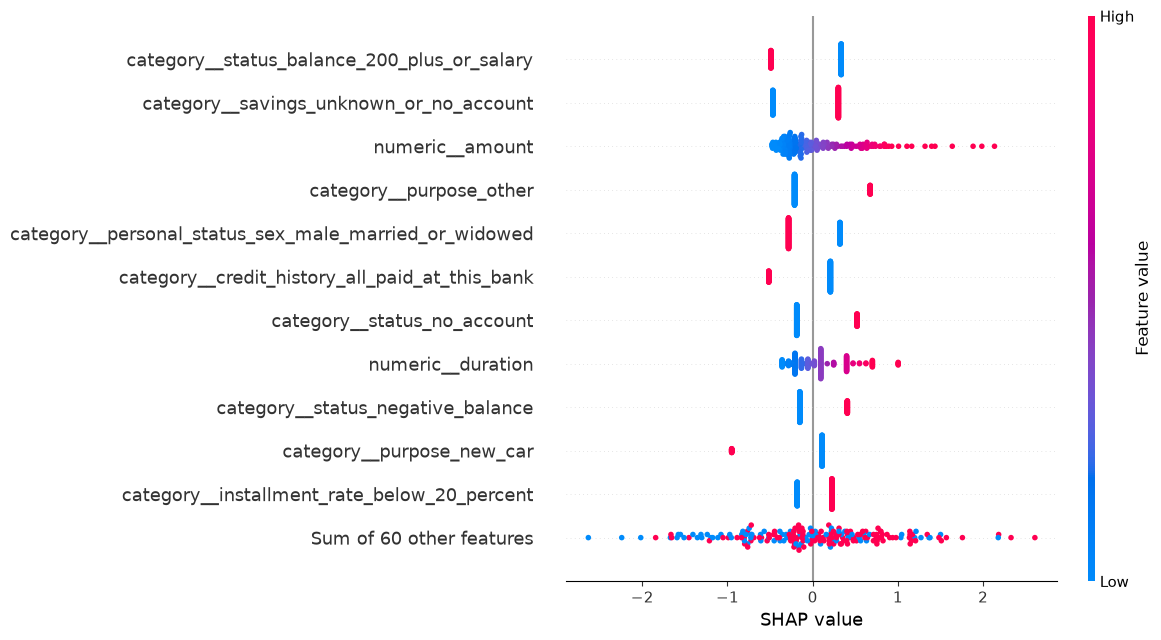

In [11]:
# transform 결과: (계약 수, 전처리 후 특성 수) 배열.
logistic_train_values = logistic_preprocessor.transform(X_train)
logistic_valid_values = logistic_preprocessor.transform(X_valid)

# max_samples로 학습 계약 전체를 SHAP 기준 데이터에 포함한다.
logistic_masker = shap.maskers.Independent(logistic_train_values, max_samples=len(logistic_train_values))
logistic_explainer = shap.LinearExplainer(logistic_estimator, logistic_masker,
                                        feature_names=list(logistic_feature_names))

# 설명 객체의 values: (계약 수, 특성 수) 배열.
logistic_explanation = logistic_explainer(logistic_valid_values)

# max_display: 표시할 항목 수, show=False: 그래프 설정 후 출력.
shap.plots.beeswarm(logistic_explanation, max_display=12, show=False)
plt.xlabel("SHAP value")
plt.gcf().set_size_inches(12, 6.5)
plt.tight_layout()
plt.show()


점 분포를 보면 다음과 같이 해석할 수 있다.

- `numeric__duration`: 빨간 점이 오른쪽, 파란 점이 왼쪽에 있다. 긴 계약 기간은 불량 점수를 높이고, 짧은 기간은 낮추는 방향으로 반영된다.
- `category__purpose_new_car`: 빨간 점이 왼쪽에 있다. 새 차 구매 목적에 해당하는 계약에서 이 정보가 불량 점수를 낮추는 방향으로 반영된다.
- `category__status_no_account`: 빨간 점이 오른쪽에 있다. 계좌가 없다는 정보가 불량 점수를 높이는 방향으로 반영된다.


### 로지스틱 회귀의 계약 한 건 설명하기

waterfall은 계약 한 건의 예측을 설명하는 그래프다.
아래쪽 기준값 `E[f(X)]`에서 시작해 각 특성의 기여를 더하면 위쪽 모델 출력 `f(x)`에 도달한다.


왼쪽에 적힌 수치 입력은 표준화한 값이고, 원핫 입력은 0 또는 1이다.

`LOGISTIC_POSITION`은 설명할 계약의 위치 번호다.


,record_id,actual,prediction,bad_class_score
validation_position,,,,
2,142,0,0,0.218213


,142
record_id,142
duration,24
amount,5084
age,42
status,negative_balance
credit_history,no_credit_or_all_paid
purpose,furniture
savings,1000_plus_DM
employment_duration,7_plus_years
installment_rate,25_to_35_percent


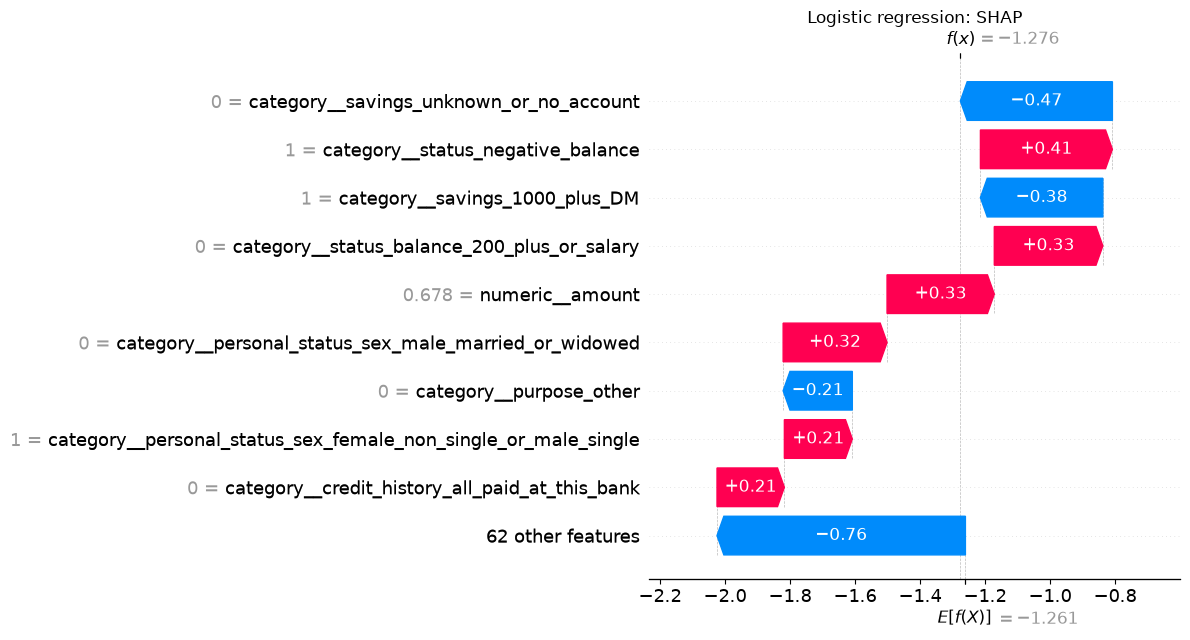

In [14]:
LOGISTIC_POSITION = 2

display(logistic_results.iloc[[LOGISTIC_POSITION]])
display(credit.loc[[X_valid.index[LOGISTIC_POSITION]], ["record_id", *CREDIT_FEATURES, "bad_credit"]].T)

# 계약 한 건의 기준값·기여도·입력값을 꺼낸다.
logistic_case = logistic_explanation[LOGISTIC_POSITION]

shap.plots.waterfall(logistic_case, max_display=10, show=False)
plt.title("Logistic regression: SHAP")
plt.gcf().set_size_inches(12, 6.5)
plt.tight_layout()
plt.show()


## 랜덤포레스트로 신용평가하기

랜덤포레스트는 입력 조건에 따라 데이터를 나누는 결정 트리 여러 개의 예측을 평균한다.
예를 들어 계약 기간과 계좌 상태가 함께 달라지는 경우처럼 여러 조건의 조합을 반영할 수 있다.
각 트리의 불량 클래스 점수를 평균해 계약의 불량 점수를 계산한다.

### 전처리와 학습

트리는 수치의 크기를 기준으로 분할하므로 수치형 변수를 원래 값으로 사용한다.
범주형 변수는 원핫 인코딩한다.


In [17]:
# passthrough: 수치 열을 그대로 전달한다.
forest_preprocessor = ColumnTransformer([
    ("numeric", "passthrough", CREDIT_NUMERIC),
    ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CREDIT_CATEGORICAL),
])

# 트리 200개, 최대 깊이 6, 잎당 최소 학습 계약 5건.
forest_model = Pipeline([
    ("preprocess", forest_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200, max_depth=6, min_samples_leaf=5,
        max_features="sqrt", random_state=SEED, n_jobs=-1
    )),
])
forest_model.fit(X_train, y_train)

# 검증 계약의 클래스와 불량 점수를 구한다.
forest_prediction = forest_model.predict(X_valid)
positive_column = list(forest_model.classes_).index(1)
forest_scores = forest_model.predict_proba(X_valid)[:, positive_column]


### 랜덤포레스트의 예측 결과

검증 데이터의 불량 계약을 몇 건 찾고 몇 건 놓쳤는지 혼동 행렬에서 확인한다.
양호 계약을 불량으로 판단한 건수도 읽고, 정밀도와 재현율을 계약 수와 연결해 설명한다.


,precision,recall,TP,FP,TN,FN
0,0.647059,0.183333,11,6,134,49


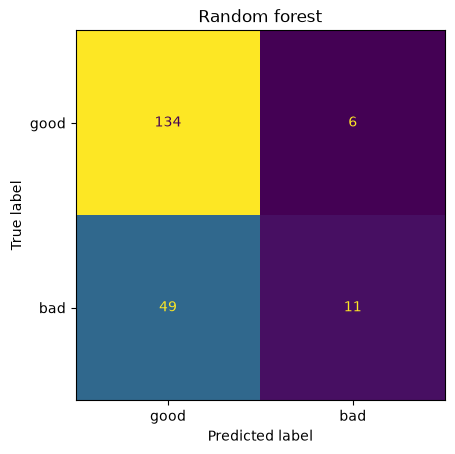

In [18]:
display(pd.DataFrame([credit_metrics(y_valid, forest_prediction)]))

ConfusionMatrixDisplay.from_predictions(
    y_valid, forest_prediction, labels=[0, 1],
    display_labels=["good", "bad"], colorbar=False
)
plt.title("Random forest")
plt.show()


### 랜덤포레스트의 오류 사례

랜덤포레스트가 잘못 예측한 계약을 확인한다.
각 사례의 실제 결과와 예측을 읽고 오탐인지 미탐인지 구분한다.


In [19]:
forest_results = pd.DataFrame({
    "record_id": credit.loc[X_valid.index, "record_id"].to_numpy(),
    "actual": y_valid.to_numpy(),
    "prediction": forest_prediction,
    "bad_class_score": forest_scores,
})
forest_results.index.name = "validation_position"

# 실제 라벨과 예측이 다른 계약을 고른다.
forest_errors = forest_results.loc[forest_results.actual != forest_results.prediction]
print("오류 계약 수:", len(forest_errors))
display(forest_errors.head(5))


오류 계약 수: 55


,record_id,actual,prediction,bad_class_score
validation_position,,,,
10,734,0,1,0.502451
11,887,1,0,0.468960
21,927,1,0,0.487079
24,825,1,0,0.316032
28,931,1,0,0.452153


### 랜덤포레스트의 전체 특성 중요도

트리의 한 노드에 양호와 불량이 섞여 있는 정도를 불순도라고 한다.
랜덤포레스트의 특성 중요도는 각 특성이 분할에서 불순도를 줄이는 데 기여한 정도를 트리 전체에서 집계한 값이다.
값이 클수록 분할에 크게 기여했으며, 점수를 높이거나 낮추는 방향은 담지 않는다.

원핫 인코딩된 범주는 각각의 열로 표시된다.
분할 후보가 많은 특성은 중요도가 높게 나타날 수 있고, 비슷한 정보를 가진 특성은 중요도를 나누어 가질 수 있다.

중요도가 높은 특성 12개와 낮은 특성 12개를 각각 확인한다. 원래 변수의 의미와 연결하고, 모델이 어떤 계약 정보를 분할에 많이 사용했는지 설명한다.


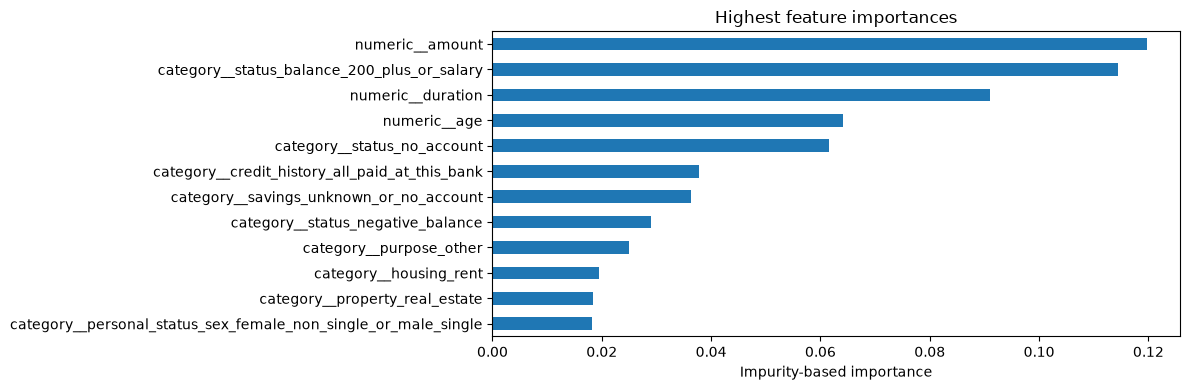

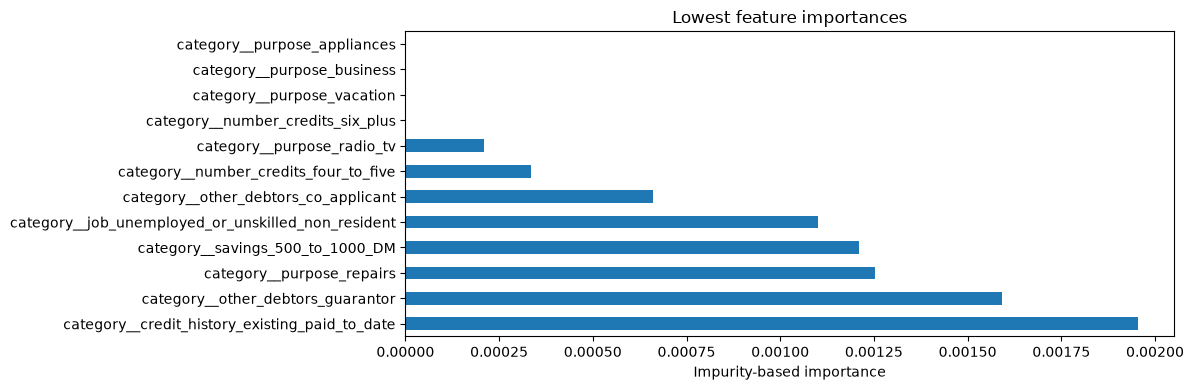

In [20]:
forest_preprocessor = forest_model.named_steps["preprocess"]
forest_estimator = forest_model.named_steps["model"]
forest_feature_names = forest_preprocessor.get_feature_names_out()

# feature_importances_: 특성별 중요도 배열, 합은 1.
importance = pd.Series(
    forest_estimator.feature_importances_, index=forest_feature_names
).sort_values()

# 중요도가 높은 특성 12개.
importance.tail(12).plot.barh(figsize=(12, 4))
plt.title("Highest feature importances")
plt.xlabel("Impurity-based importance")
plt.tight_layout()
plt.show()

# 중요도가 낮은 특성 12개. 가장 작은 값이 위에 오도록 정렬한다.
importance.head(12).sort_values(ascending=False).plot.barh(figsize=(12, 4))
plt.title("Lowest feature importances")
plt.xlabel("Impurity-based importance")
plt.tight_layout()
plt.show()


### 랜덤포레스트의 SHAP

TreeExplainer는 트리의 분할 구조를 이용해 SHAP 값을 계산한다. 여러 특성의 조합을 반영하므로, 같은 입력값도 계약의 다른 정보에 따라 SHAP 값이 달라질 수 있다.

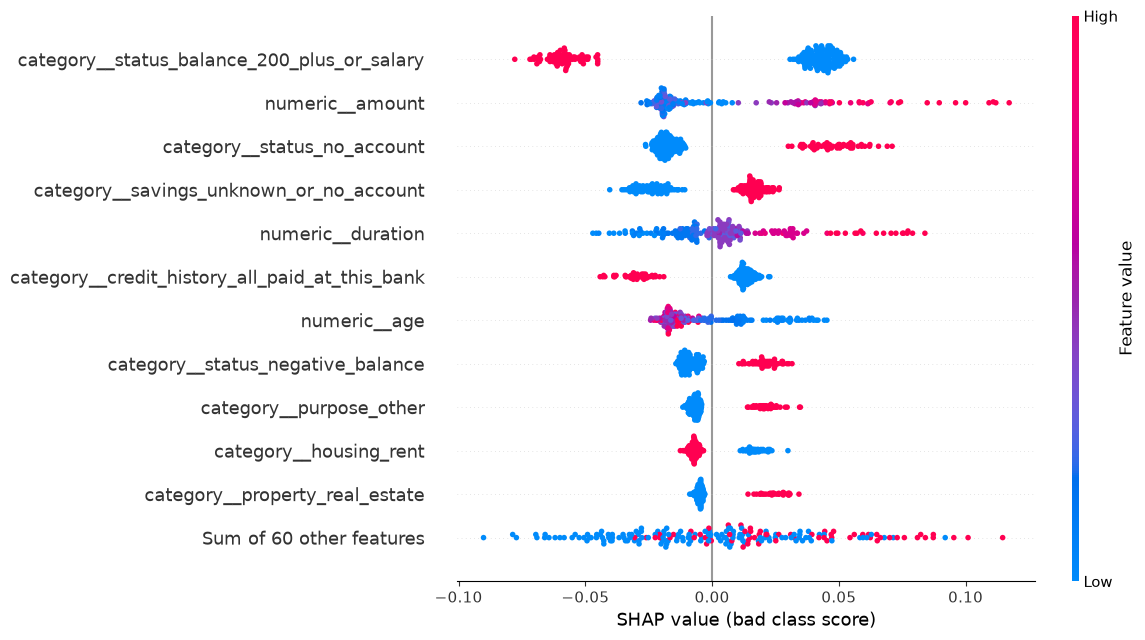

In [21]:
forest_valid_values = forest_preprocessor.transform(X_valid)
forest_explainer = shap.TreeExplainer(
    forest_estimator, feature_perturbation="tree_path_dependent", model_output="raw"
)

# values: (계약 수, 특성 수, 클래스 수) 배열.
all_explanations = forest_explainer(forest_valid_values)

# 불량 클래스의 기여도만 선택한다.
positive_column = list(forest_estimator.classes_).index(1)
forest_explanation = all_explanations[:, :, positive_column]
forest_explanation.feature_names = list(forest_feature_names)

shap.plots.beeswarm(forest_explanation, max_display=12, show=False)
plt.xlabel("SHAP value (bad class score)")
plt.gcf().set_size_inches(12, 6.5)
plt.tight_layout()
plt.show()


### 랜덤포레스트의 계약 한 건 설명하기

waterfall은 계약 한 건의 예측을 설명하는 그래프다.
아래쪽 기준값 `E[f(X)]`에서 시작해 각 특성의 기여를 더하면 위쪽 모델 출력 `f(x)`에 도달한다.

왼쪽에 적힌 수치 입력은 원래 값이고, 원핫 입력은 0 또는 1이다.

`FOREST_POSITION`은 설명할 계약의 위치 번호다. 0은 검증 데이터의 첫 계약을 가리킨다.


,record_id,actual,prediction,bad_class_score
validation_position,,,,
2,142,0,0,0.305091


,142
record_id,142
duration,24
amount,5084
age,42
status,negative_balance
credit_history,no_credit_or_all_paid
purpose,furniture
savings,1000_plus_DM
employment_duration,7_plus_years
installment_rate,25_to_35_percent


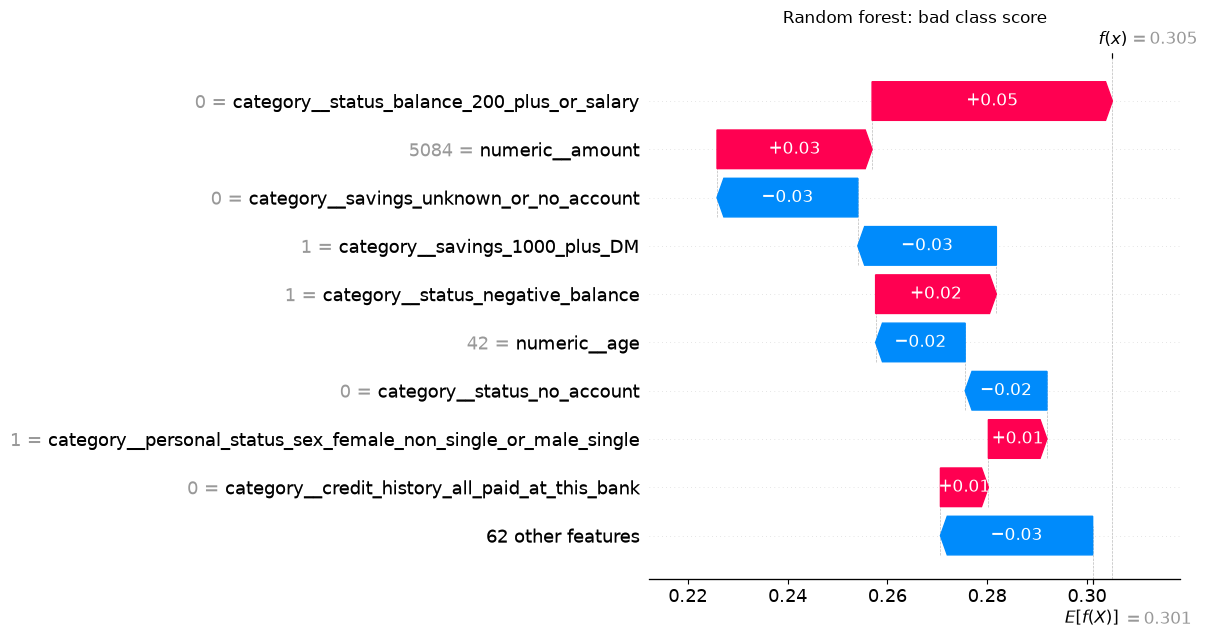

In [24]:
FOREST_POSITION = 2

display(forest_results.iloc[[FOREST_POSITION]])
display(credit.loc[[X_valid.index[FOREST_POSITION]], ["record_id", *CREDIT_FEATURES, "bad_credit"]].T)

# 계약 한 건의 기준값·기여도·입력값을 꺼낸다.
forest_case = forest_explanation[FOREST_POSITION]

shap.plots.waterfall(forest_case, max_display=10, show=False)
plt.title("Random forest: bad class score")
plt.gcf().set_size_inches(12, 6.5)
plt.tight_layout()
plt.show()


## ROC·PR 곡선으로 평가하기

### 임계값에 따라 달라지는 예측

모델은 계약마다 불량 클래스에 대한 예측 확률을 0~1 사이의 값으로 출력한다. 이 점수를 양호·불량으로 나누는 기준이 임계값(Threshold)이다. 점수가 임계값 이상이면 불량, 미만이면 양호로 분류한다.

예를 들어 불량 점수가 0.4인 계약은 임계값이 0.5일 때 양호로, 임계값이 0.3일 때 불량으로 분류된다.

학습된 모델과 예측 점수를 그대로 두고 임계값을 바꿔 가며 평가하면, 이런 변화를 곡선으로 볼 수 있다.
ROC와 PR 곡선의 각 점은 한 임계값에서 얻은 평가 결과를 나타낸다.

### ROC 곡선

ROC 곡선은 양호 계약에서 생기는 오탐과 불량 계약을 찾아내는 정도를 함께 보여준다.

| 축 | 지표 | 의미 |
| --- | --- | --- |
| 가로축 | 오탐률(False Positive Rate, FPR) = `FP / (FP + TN)` | 실제 양호 계약 중 불량으로 잘못 분류한 비율 |
| 세로축 | 재현율(Recall, TPR) = `TP / (TP + FN)` | 실제 불량 계약 중 불량으로 찾아낸 비율 |

임계값에 따라 ROC 곡선 위에서 선택하는 위치가 달라진다.

- 임계값을 낮추면 더 많은 계약이 불량으로 분류된다. 실제 불량을 찾아낸 TP와 양호 계약을 잘못 분류한 FP가 늘어날 수 있으므로, 재현율과 오탐률은 증가하거나 유지된다. 곡선에서는 오른쪽·위쪽 방향으로 이동한다.
- 임계값을 높이면 불량으로 분류되는 계약이 줄어든다. TP와 FP가 줄어들 수 있으므로, 재현율과 오탐률은 감소하거나 유지된다. 곡선에서는 왼쪽·아래쪽 방향으로 이동한다. 실제 불량을 놓치는 FN은 늘어날 수 있다.

ROC 곡선에서는 왼쪽 위에 가까울수록 좋다. 왼쪽은 오탐률이 낮아 양호 계약을 잘못 분류하는 경우가 적다는 뜻이고, 위쪽은 재현율이 높아 실제 불량을 많이 찾아낸다는 뜻이다.

### ROC AUC

AUC는 곡선 아래의 면적(Area Under the Curve)이다. ROC AUC는 임계값을 바꾸며 얻은 ROC 곡선을 0~1 사이의 숫자로 요약한다.
완벽하게 순위를 구분하면 1이고, 무작위 순위의 기준은 0.5다.

ROC AUC가 높을수록 실제 불량 계약에 양호 계약보다 높은 점수를 주는 경향이 강하다. 여러 임계값에서의 결과를 종합하므로, 하나의 임계값을 정하기 전에 모델의 구분 능력을 비교할 수 있다.

임계값은 점수가 얼마 이상일 때 불량으로 분류할지 정하는 기준이다. ROC AUC로 모델의 구분 능력을 비교하고, 임계값을 선택할 때는 정밀도·재현율과 오탐·미탐 건수를 함께 확인한다.
예측 확률이 실제 불량 발생 비율과 얼마나 잘 맞는지는 확률 보정의 관점에서 별도로 평가한다.

### PR 곡선

PR은 Precision(정밀도)과 Recall(재현율)을 뜻한다. 이 곡선은 불량을 얼마나 많이 찾는지와 불량으로 판단한 결과가 얼마나 정확한지를 함께 보여준다.

| 축 | 지표 | 의미 |
| --- | --- | --- |
| 가로축 | 재현율(Recall) = `TP / (TP + FN)` | 실제 불량 계약 중 찾아낸 비율 |
| 세로축 | 정밀도(Precision) = `TP / (TP + FP)` | 불량으로 분류한 계약 중 실제 불량인 비율 |

PR 곡선에서는 오른쪽 위에 가까울수록 좋다. 오른쪽은 재현율이 높아 실제 불량을 많이 찾아낸다는 뜻이고, 위쪽은 정밀도가 높아 불량으로 판단한 계약 중 실제 불량의 비율이 높다는 뜻이다.

임계값에 따른 PR 곡선의 변화는 다음과 같다.

- 임계값을 낮추면 불량으로 분류하는 계약이 늘어나고, 재현율은 증가하거나 유지된다. 곡선에서는 오른쪽 방향으로 이동한다.
- 임계값을 높이면 불량으로 분류하는 계약이 줄어들고, 재현율은 감소하거나 유지된다. 곡선에서는 왼쪽 방향으로 이동한다.

정밀도는 불량으로 분류한 계약에 실제 불량과 양호가 얼마나 섞여 있는지에 따라 달라진다. 임계값을 바꿀 때 새로 포함되거나 제외되는 계약의 실제 라벨에 따라 위아래로 오르내릴 수 있다.
PR 곡선의 가로 점선은 데이터의 불량 비율이다. 모든 계약을 불량으로 분류하면 재현율은 1, 정밀도는 이 비율이 된다.

불량을 놓치는 일을 줄이고 싶다면 임계값을 낮추면서 오탐이 얼마나 늘어나는지 살펴본다. 양호 계약을 불량으로 판단하는 일을 줄이고 싶다면 임계값을 높이면서 놓치는 불량이 얼마나 늘어나는지 살펴본다.
임계값은 검증 데이터에서 비교해 선택하고, 확정한 기준을 테스트 데이터에 적용한다.


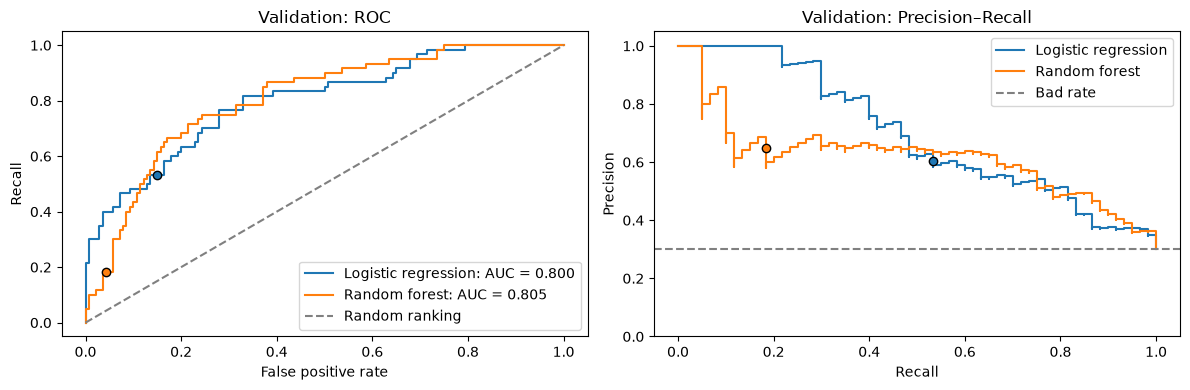

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for model_name, scores, color in [
    ("Logistic regression", logistic_scores, "tab:blue"),
    ("Random forest", forest_scores, "tab:orange"),
]:
    # 실제 라벨과 불량 점수로 임계값별 오탐률·재현율을 구한다.
    fpr, tpr, _ = roc_curve(y_valid, scores)
    roc_auc = roc_auc_score(y_valid, scores)

    # 반환값은 임계값별 정밀도·재현율과 임계값 배열이다.
    precision, recall, _ = precision_recall_curve(y_valid, scores)

    # 각 모델의 임계값 0.5 위치를 곡선과 같은 색의 점으로 표시한다.
    threshold_prediction = scores >= 0.5
    tn, fp, fn, tp = confusion_matrix(y_valid, threshold_prediction, labels=[0, 1]).ravel()
    threshold_fpr = fp / (fp + tn)
    threshold_recall = recall_score(y_valid, threshold_prediction)
    threshold_precision = precision_score(y_valid, threshold_prediction, zero_division=0)

    axes[0].plot(fpr, tpr, color=color, label=f"{model_name}: AUC = {roc_auc:.3f}")
    axes[0].scatter(threshold_fpr, threshold_recall, color=color, edgecolors="black", zorder=3)
    axes[1].step(recall, precision, where="post", color=color, label=model_name)
    axes[1].scatter(threshold_recall, threshold_precision, color=color, edgecolors="black", zorder=3)

axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
axes[0].set(xlabel="False positive rate", ylabel="Recall", title="Validation: ROC")
axes[0].legend()

axes[1].axhline(y_valid.mean(), linestyle="--", color="gray", label="Bad rate")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Validation: Precision–Recall")
axes[1].set_ylim(0, 1.05)
axes[1].legend()

plt.tight_layout()
plt.show()


### 두 모델의 검증 결과

파란 곡선은 로지스틱 회귀, 주황 곡선은 랜덤포레스트의 결과다. 검은 테두리가 있는 점은 각 모델의 임계값 0.5 결과이며, 곡선과 같은 색으로 표시했다. 임계값을 바꾸면 각 모델의 곡선 위에서 선택하는 위치가 달라진다.

임계값 0.5에서 로지스틱 회귀는 랜덤포레스트보다 재현율이 높고, 정밀도는 낮다. 실제 불량을 더 많이 찾아내는 동시에 양호 계약을 불량으로 판단하는 오탐도 더 많다.
랜덤포레스트의 ROC AUC가 조금 더 높으며, PR 곡선에서는 비교하는 재현율 구간에 따라 두 모델의 정밀도 차이가 달라진다.


## 실습: 모델 설정을 바꾸고 결과 비교하기

로지스틱 회귀의 계수와 SHAP 값, 랜덤포레스트의 전체 특성 중요도와 SHAP 값을 바탕으로 입력 특성이나 하이퍼파라미터를 하나 바꾼다.
학습 데이터로 모델을 다시 학습하고, 같은 검증 데이터에서 변경 전후의 정밀도·재현율·ROC AUC를 비교한다. 성능이 높아지거나 낮아진 이유를 설명한다.
검증 데이터의 ROC·PR 곡선을 확인하고, 불량을 놓치는 경우와 양호를 불량으로 판단하는 경우를 고려해 임계값을 선택한다.

모델과 임계값을 확정한 뒤, 선택한 모델로 `X_test`의 불량 점수를 구한다. 확정한 임계값을 적용한 예측과 `y_test`를 비교해 최종 성능을 평가한다.
테스트 결과는 검증 결과와의 차이와 모델의 한계를 해석하는 데 사용한다.
